In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/baseline_features.csv")

train = df[df["split"] == "train"].copy()

print("Training matches:", len(train))
train.head()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 5.3 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.
Training matches: 106288


,SourceRow,MatchDate,year,Country,Division,HomeTeam,AwayTeam,FTResult,y,elo_diff,...,h2h_gd,h2h_draw_rate,q_log_H_D,q_log_A_D,q_H,q_D,q_A,home_recent_points_sum,away_recent_points_sum,split
0,411,2000-09-05,2000,FRA,F1,Monaco,Marseille,A,2,87.64,...,0.0,0.0,0.543615,-0.254892,0.492454,0.285941,0.221604,8,7,train
1,438,2000-09-06,2000,FRA,F1,Bastia,Lille,H,0,11.73,...,0.0,0.0,0.656333,-0.318454,0.527420,0.273599,0.198981,9,10,train
2,439,2000-09-06,2000,FRA,F1,Guingamp,Toulouse,H,0,13.41,...,0.0,0.0,0.333144,-0.032790,0.414901,0.297346,0.287754,1,3,train
3,440,2000-09-06,2000,FRA,F1,Lens,Auxerre,H,0,108.50,...,0.0,0.0,0.603535,-0.247836,0.506662,0.277081,0.216258,11,9,train
4,441,2000-09-06,2000,FRA,F1,Metz,Strasbourg,H,0,65.38,...,0.0,0.0,0.562119,-0.490623,0.521110,0.297033,0.181857,5,3,train


In [5]:
train["h2h_count"].describe()

count    106288.000000
mean          8.824637
std           8.376315
min           0.000000
25%           2.000000
50%           6.000000
75%          13.000000
max          65.000000
Name: h2h_count, dtype: float64

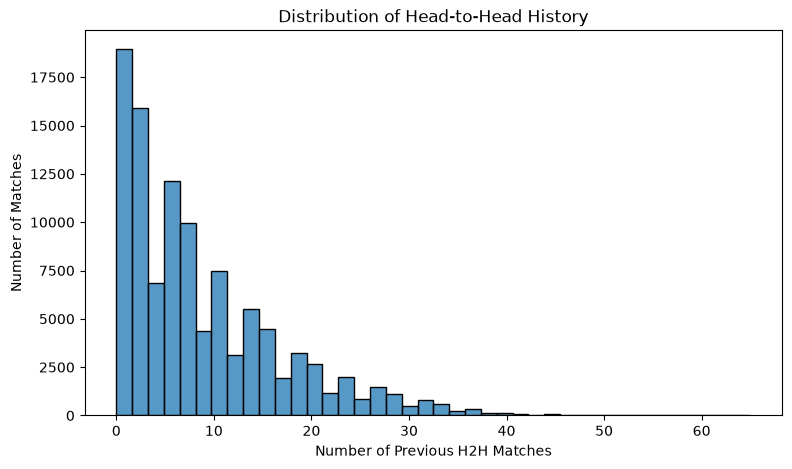

In [6]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train,
    x="h2h_count",
    bins=40
)

plt.xlabel("Number of Previous H2H Matches")
plt.ylabel("Number of Matches")
plt.title("Distribution of Head-to-Head History")

plt.show()

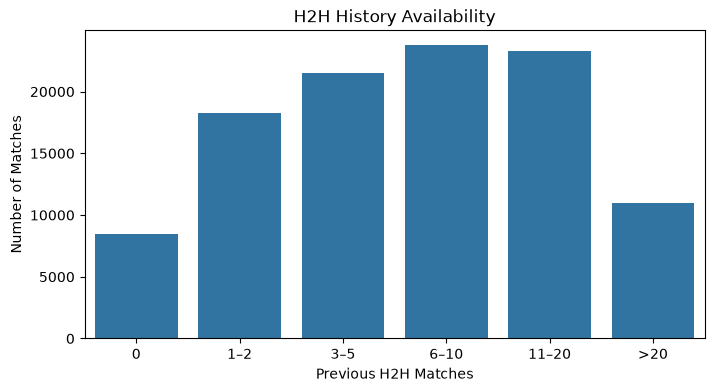

In [7]:
bins = [-1, 0, 2, 5, 10, 20, np.inf]
labels = ["0", "1–2", "3–5", "6–10", "11–20", ">20"]

h2h_groups = pd.cut(
    train["h2h_count"],
    bins=bins,
    labels=labels
)

counts = h2h_groups.value_counts().sort_index()

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values)

plt.xlabel("Previous H2H Matches")
plt.ylabel("Number of Matches")
plt.title("H2H History Availability")

plt.show()

In [8]:
bins = [-np.inf, -1, -0.5, 0, 0.5, 1, np.inf]
labels = ["<-1", "-1 to -0.5", "-0.5 to 0",
          "0 to 0.5", "0.5 to 1", ">1"]

train["ppg_group"] = pd.cut(
    train["recent_ppg_diff"],
    bins=bins,
    labels=labels
)

result = pd.crosstab(
    train["ppg_group"],
    train["FTResult"],
    normalize="index"
) * 100

result

FTResult,A,D,H
ppg_group,,,
<-1,39.032275,27.463035,33.504690
-1 to -0.5,32.573312,27.532450,39.894238
-0.5 to 0,28.106035,28.292193,43.601772
0 to 0.5,24.181626,27.877508,47.940866
0.5 to 1,21.373871,25.694365,52.931764
>1,15.862069,22.374509,61.763422


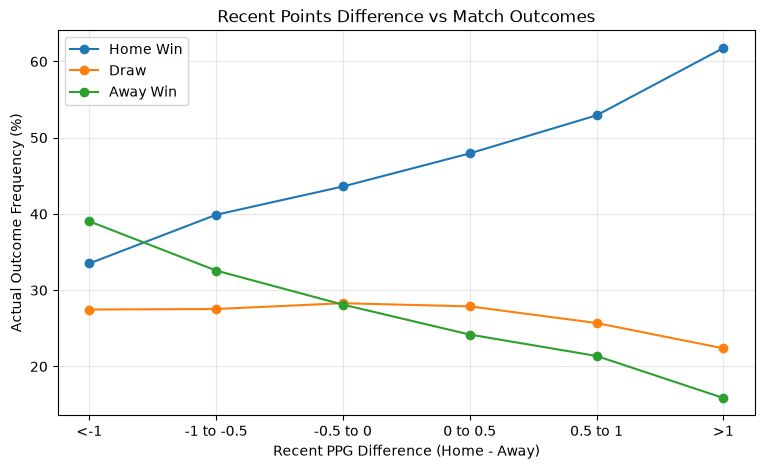

In [9]:
result[["H", "D", "A"]].plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.xlabel("Recent PPG Difference (Home - Away)")
plt.ylabel("Actual Outcome Frequency (%)")
plt.title("Recent Points Difference vs Match Outcomes")
plt.legend(["Home Win", "Draw", "Away Win"])
plt.grid(alpha=0.3)
plt.show()

In [10]:
bins = [-np.inf, -2, -1, 0, 1, 2, np.inf]
labels = ["<-2", "-2 to -1", "-1 to 0",
          "0 to 1", "1 to 2", ">2"]

train["gd_group"] = pd.cut(
    train["recent_gd_diff"],
    bins=bins,
    labels=labels
)

gd_result = pd.crosstab(
    train["gd_group"],
    train["FTResult"],
    normalize="index"
) * 100

gd_result[["H", "D", "A"]]

FTResult,H,D,A
gd_group,,,
<-2,27.430649,26.151360,46.417991
-2 to -1,35.930945,28.310208,35.758847
-1 to 0,42.823537,28.482673,28.693790
0 to 1,49.903459,27.062091,23.034450
1 to 2,57.972881,23.907280,18.119839
>2,69.469127,18.364092,12.166781


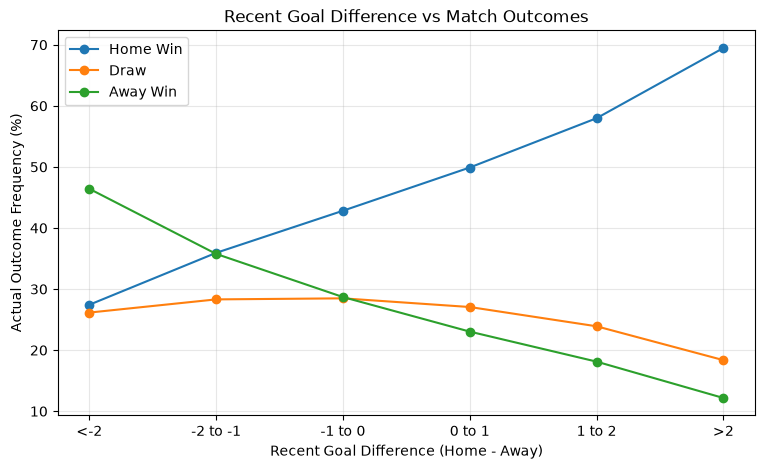

In [11]:
gd_result[["H", "D", "A"]].plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.xlabel("Recent Goal Difference (Home - Away)")
plt.ylabel("Actual Outcome Frequency (%)")
plt.title("Recent Goal Difference vs Match Outcomes")
plt.legend(["Home Win", "Draw", "Away Win"])
plt.grid(alpha=0.3)
plt.show()

In [12]:
bins = [-0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0]
labels = ["0–0.1", "0.1–0.2", "0.2–0.3",
          "0.3–0.4", "0.4–0.5", ">0.5"]

train["draw_group"] = pd.cut(
    train["recent_draw_rate_mean"],
    bins=bins,
    labels=labels
)

draw_result = train.groupby(
    "draw_group", observed=True
).agg(
    matches=("FTResult", "size"),
    draw_rate=("FTResult", lambda x: (x == "D").mean() * 100)
)

draw_result

,matches,draw_rate
draw_group,,
0–0.1,22325,26.194849
0.1–0.2,27924,26.117318
0.2–0.3,26919,27.367287
0.3–0.4,17650,27.626062
0.4–0.5,8175,27.840979
>0.5,3295,28.558422


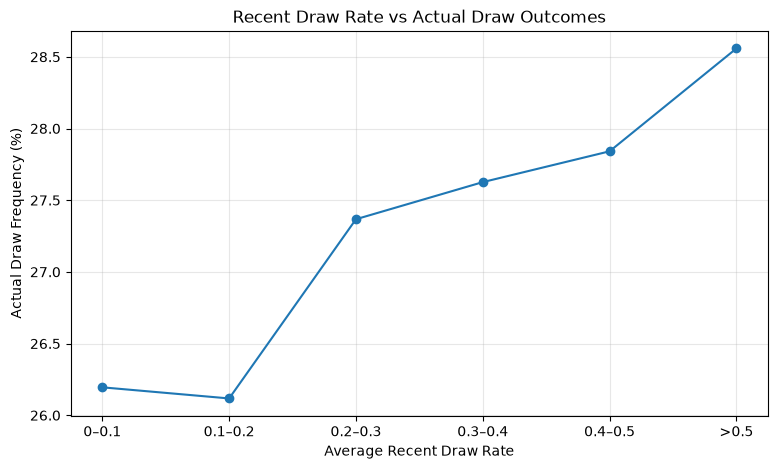

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    draw_result.index.astype(str),
    draw_result["draw_rate"],
    marker="o"
)

plt.xlabel("Average Recent Draw Rate")
plt.ylabel("Actual Draw Frequency (%)")
plt.title("Recent Draw Rate vs Actual Draw Outcomes")
plt.grid(alpha=0.3)
plt.show()

In [14]:
features = [
    "elo_diff",
    "recent_ppg_diff",
    "recent_gd_diff",
    "recent_draw_rate_mean"
]

train[features].corr().round(3)

,elo_diff,recent_ppg_diff,recent_gd_diff,recent_draw_rate_mean
elo_diff,1.000,0.559,0.598,0.010
recent_ppg_diff,0.559,1.000,0.882,0.012
recent_gd_diff,0.598,0.882,1.000,0.013
recent_draw_rate_mean,0.010,0.012,0.013,1.000
